In [2]:
#!pip install tensorflow
#!pip install matplotlib
#!pip install scikit-learn
#!pip install tqdm


## JUST FOR CUDA USERS:
#from tensorflow.keras import backend as K
import tensorflow as tf
#K.clear_session()
#tf.compat.v1.reset_default_graph()
tf.config.set_visible_devices([], 'GPU')

2025-04-27 22:17:01.558793: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745813821.575764   59104 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745813821.580787   59104 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1745813821.594426   59104 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1745813821.594446   59104 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1745813821.594447   59104 computation_placer.cc:177] computation placer alr

## APRENDIZAJE FEDERADO.

El aprendizaje federado consiste en entrenar un modelo localmente con un subconjunto de datos, para después computar un modelo global (idéntico) que será desplegado como un servicio.

Para simular una situación de aprendizaje federado, usaremos la bien-conocida base de datos MNIST para interpretar número escritos a mano, y la dividiremos en cinco partes (en su caso, será en cuantos miembros de su equipo tengan).

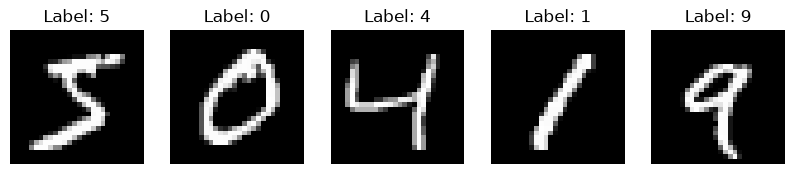

15000
Frecuencia de números: {0: 1480, 1: 1685, 2: 1489, 3: 1533, 4: 1461, 5: 1356, 6: 1479, 7: 1567, 8: 1462, 9: 1488}
Primeros ejemplos (labels): [5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1]
15000
Frecuencia de números: {0: 1481, 1: 1685, 2: 1490, 3: 1533, 4: 1461, 5: 1355, 6: 1479, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [7, 7, 0, 7, 7, 7, 3, 3, 7, 0, 0, 3, 7, 3, 7]
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1490, 3: 1532, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
15000
Frecuencia de números: {0: 1481, 1: 1686, 2: 1489, 3: 1533, 4: 1460, 5: 1355, 6: 1480, 7: 1566, 8: 1463, 9: 1487}
Primeros ejemplos (labels): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 9, 9]


In [1]:
import tensorflow as tf
import numpy as np

train, test = tf.keras.datasets.mnist.load_data()

x_train, x_test = np.expand_dims(train[0] / 255.0, -1), np.expand_dims(test[0] / 255.0, -1)
y_train, y_test = train[1], test[1]

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()


## Data split para simular cinco datos aparte.
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=4)

folds = skf.split(x_train, y_train)

local_data = [(x_train[tsix], y_train[tsix]) for trix, tsix in folds]

for x in local_data:
    print(len(x[0]))
    print(f"Frecuencia de números: { {int(y):list(x[1]).count(y) for y in set(x[1])} }")
    print(f"Primeros ejemplos (labels): {[int(y) for y in list(x[1])[:15]]}")

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8682 - loss: 0.4770 - val_accuracy: 0.9201 - val_loss: 0.2777
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 802us/step - accuracy: 0.9367 - loss: 0.2220 - val_accuracy: 0.9355 - val_loss: 0.2031
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 984us/step - accuracy: 0.9540 - loss: 0.1614 - val_accuracy: 0.9477 - val_loss: 0.1741
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step - accuracy: 0.9627 - loss: 0.1234 - val_accuracy: 0.9548 - val_loss: 0.1478
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step - accuracy: 0.9691 - loss: 0.0984 - val_accuracy: 0.9566 - val_loss: 0.1446
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 789us/step - accuracy: 0.9763 - loss: 0.0782 - val_accuracy: 0.9540 - val_loss: 0.1602
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - accuracy: 0.9807 - loss: 0.0635 - val_accuracy: 0.9577 - val_loss: 0.1558
Epoch 8/15
469/

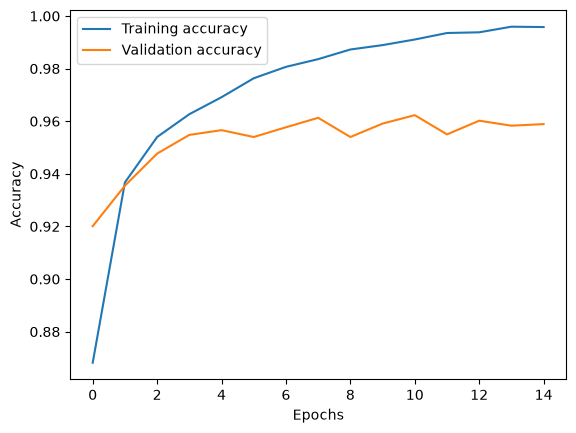

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_1, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 992us/step - accuracy: 0.8694 - loss: 0.4589 - val_accuracy: 0.9257 - val_loss: 0.2579
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 810us/step - accuracy: 0.9330 - loss: 0.2211 - val_accuracy: 0.9405 - val_loss: 0.1959
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 810us/step - accuracy: 0.9493 - loss: 0.1684 - val_accuracy: 0.9432 - val_loss: 0.1842
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step - accuracy: 0.9608 - loss: 0.1322 - val_accuracy: 0.9507 - val_loss: 0.1689
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step - accuracy: 0.9670 - loss: 0.1075 - val_accuracy: 0.9561 - val_loss: 0.1525
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 817us/step - accuracy: 0.9729 - loss: 0.0895 - val_accuracy: 0.9583 - val_loss: 0.1514
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 796us/step - accuracy: 0.9769 - loss: 0.0740 - val_accuracy: 0.9551 - val_loss: 0.1591
Epoch 8/15


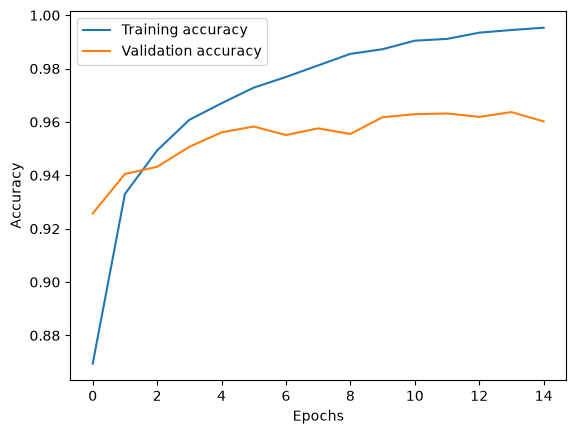

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_2, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 962us/step - accuracy: 0.8516 - loss: 0.5011 - val_accuracy: 0.9096 - val_loss: 0.3040
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 791us/step - accuracy: 0.9219 - loss: 0.2517 - val_accuracy: 0.9394 - val_loss: 0.2099
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.9437 - loss: 0.1858 - val_accuracy: 0.9447 - val_loss: 0.1921
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step - accuracy: 0.9548 - loss: 0.1452 - val_accuracy: 0.9511 - val_loss: 0.1660
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step - accuracy: 0.9633 - loss: 0.1181 - val_accuracy: 0.9519 - val_loss: 0.1644
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - accuracy: 0.9707 - loss: 0.0958 - val_accuracy: 0.9530 - val_loss: 0.1655
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 779us/step - accuracy: 0.9771 - loss: 0.0794 - val_accuracy: 0.9561 - val_loss: 0.1558
Epoch 8/15


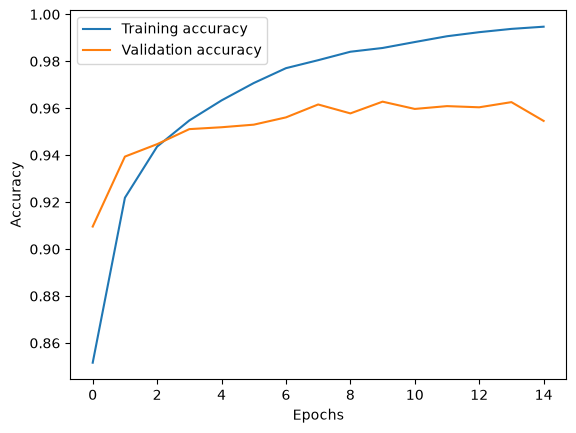

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

DEBUGGG
<Functional name=functional_3, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8632 - loss: 0.4760 - val_accuracy: 0.9174 - val_loss: 0.2739
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - accuracy: 0.9312 - loss: 0.2236 - val_accuracy: 0.9344 - val_loss: 0.2095
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - accuracy: 0.9491 - loss: 0.1685 - val_accuracy: 0.9394 - val_loss: 0.2063
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 788us/step - accuracy: 0.9602 - loss: 0.1343 - val_accuracy: 0.9488 - val_loss: 0.1716
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - accuracy: 0.9681 - loss: 0.1089 - val_accuracy: 0.9472 - val_loss: 0.1745
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 860us/step - accuracy: 0.9715 - loss: 0.0903 - val_accuracy: 0.9500 - val_loss: 0.1733
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step - accuracy: 0.9769 - loss: 0.0747 - val_accuracy: 0.9498 - val_loss: 0.1751
Epoch 8/15
46

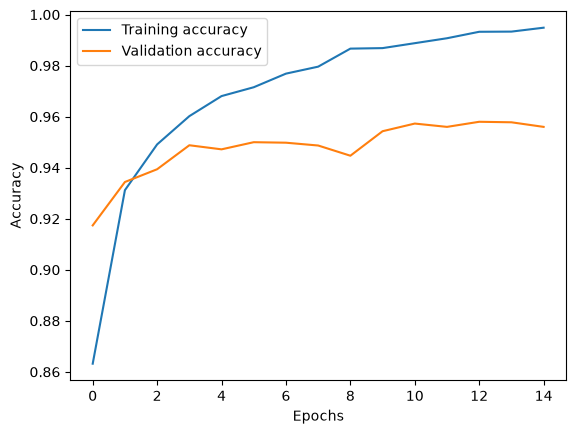

FOLD (array([[[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]]],


       [[[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        [[0.],
         [0.],
         [0.],
         ...,
         [0.],
         [0.],
         [0.]],

        ...,

        [[

In [2]:
from sklearn.metrics import classification_report
def train_and_verify(local_model, local_data, epochs, x_test, y_test, save_name):

    print("DEBUGGG")
    print(local_model)
    print(local_data[0].shape)
    print(local_data[1].shape)
    
    history = local_model.fit(local_data[0], local_data[1], epochs=epochs, validation_data=(x_test, y_test))
    y_pred = local_model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    print(classification_report(y_test, y_pred_classes))

    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    local_model.save(save_name)

# Entrenamientos locales. Cada uno de estos deben hacerse en computadoras aparte.
from model_2 import build
from tqdm import tqdm
for x in tqdm(range(len(local_data)), desc=f"FOLD {x}"):
    local_model = build.build_model()
    train_and_verify(local_model, local_data[x], 15, x_test, y_test, f"lmodel_{x}.keras")

In [3]:
local_model = build.build_model()

print("INPUT:", local_model.input_shape)
print("OUTPUT:", local_model.output_shape)

local_model.summary()

INPUT: (None, 28, 28, 1)
OUTPUT: (None, 10)


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
## Abrir los modelos:

import os
loaded_local_models = [tf.keras.models.load_model(os.path.join(root, file)) for root, dirs, files in os.walk("./") for file in files if file.endswith('.keras')]

for i in range(len(loaded_local_models)-1):
    assert loaded_local_models[i].summary() == loaded_local_models[i+1].summary(), "Models have different architectures"

/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop_22', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop_2', because it has 8 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 55,052 (215.05 KB)

## Debug

In [5]:
local_weights = [x.get_weights() for x in loaded_local_models]
averaged_weights = [np.mean(np.array(weights), axis=0) for weights in zip(*local_weights)]

global_model = build.build_model()
global_model.set_weights(averaged_weights)

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = global_model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

global_model.save('global_model.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       980
           1       0.00      0.00      0.00      1135
           2       0.30      0.97      0.46      1032
           3       0.00      0.00      0.00      1010
           4       0.98      0.32      0.49       982
           5       0.16      0.97      0.27       892
           6       0.00      0.00      0.00       958
           7       0.40      0.29      0.34      1028
           8       0.43      0.01      0.01       974
           9       0.00      0.00      0.00      1009

    accuracy                           0.25     10000
   macro avg       0.23      0.26      0.16     10000
weighted avg       0.22      0.25      0.16     10000



/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 671us/step - accuracy: 0.9212 - loss: 0.2756 - val_accuracy: 0.9583 - val_loss: 0.1374
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 563us/step - accuracy: 0.9622 - loss: 0.1282 - val_accuracy: 0.9671 - val_loss: 0.1072
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 581us/step - accuracy: 0.9712 - loss: 0.0971 - val_accuracy: 0.9684 - val_loss: 0.1025
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 590us/step - accuracy: 0.9763 - loss: 0.0790 - val_accuracy: 0.9721 - val_loss: 0.0933
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 560us/step - accuracy: 0.9806 - loss: 0.0680 - val_accuracy: 0.9681 - val_loss: 0.1081
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 582us/step - accuracy: 0.9826 - loss: 0.0585 - val_accuracy: 0.9745 - val_loss: 0.0978
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 560us/step - accuracy: 0.9845 - loss: 0.0521 - val_accuracy: 0.9736 - val_loss: 0.1135
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 589us/step - accuracy: 0.9860 -

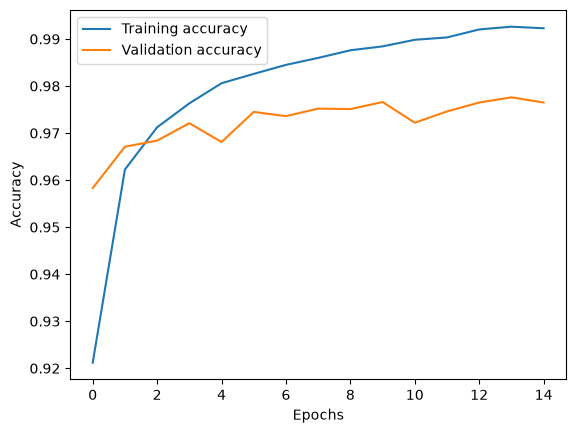

In [6]:
## VS A NORMAL GLOBLA MODEL TRAINED IN A SINGLE DEVICE:

model = build.build_model()

history = model.fit(x_train, y_train, epochs=15, validation_data=(x_test, y_test))

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

# Optionally, plot training history
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Bibliography:

https://www.tensorflow.org/guide/keras/training_with_built_in_methods
